### CẤU HÌNH LOGGING (GHI RA CONSOLE + FILE LOG)

In [2]:
from pathlib import Path
import logging
import sys
import os

LOG_DIR = Path("../docs/logs")
LOG_DIR.mkdir(parents=True, exist_ok=True)

LOG_FILE = LOG_DIR / "practice4.log"

log = logging.getLogger("Practice4")
log.setLevel(logging.INFO)
log.propagate = False

# Xóa handler cũ nếu chạy lại cell trong Jupyter
if log.hasHandlers():
    log.handlers.clear()

formatter = logging.Formatter(
    fmt="%(asctime)s | %(levelname)-8s | %(message)s",
    datefmt="%Y-%m-%d %H:%M:%S"
)

file_handler = logging.FileHandler(
    LOG_FILE,
    mode="w",
    encoding="utf-8"
)
file_handler.setFormatter(formatter)

log.addHandler(file_handler)
log.info("Khởi tạo hệ thống logging thành công.")
log.info("Log file: %s", LOG_FILE.resolve())

### Khởi tạo thư viện

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
from pathlib import Path

color_pal = sns.color_palette()

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

### Đọc dữ liệu

In [4]:
DATA_PATH = Path("../datasets")
processed_file = DATA_PATH / "processed" / "electricity_load_weather_hourly.csv"

In [5]:
df = pd.read_csv(processed_file)

df["time"] = pd.to_datetime(df["time"], utc=True)
df = df.sort_values("time").reset_index(drop=True)
num_cols = ["load", "temperature", "humidity", "wind_speed"]

df.head()

,time,load,temperature,humidity,wind_speed
0,2014-12-31 23:00:00+00:00,25385.0,-5.825,63.0,1.0
1,2015-01-01 00:00:00+00:00,24382.0,-5.825,63.0,1.0
2,2015-01-01 01:00:00+00:00,22734.0,-6.964,64.0,1.0
3,2015-01-01 02:00:00+00:00,21286.0,-6.964,64.0,1.0
4,2015-01-01 03:00:00+00:00,20264.0,-6.964,64.0,1.0


### **Chia dữ liệu theo thời gian**


In [6]:
from sklearn.preprocessing import StandardScaler

# Tạo bản sao riêng để chia tập và modeling
df_model = df.copy()


In [7]:
# Xác định vị trí chia dữ liệu
n = len(df_model)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Chia dữ liệu theo thứ tự thời gian, không shuffle
train_df = df_model.iloc[:train_end].copy()
val_df = df_model.iloc[train_end:val_end].copy()
test_df = df_model.iloc[val_end:].copy()

In [8]:
# Kiểm tra kích thước các tập
split_summary = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Samples": [
        len(train_df),
        len(val_df),
        len(test_df)
    ],
    "Percentage": [
        len(train_df) / n * 100,
        len(val_df) / n * 100,
        len(test_df) / n * 100
    ],
    "Start Time": [
        train_df["time"].min(),
        val_df["time"].min(),
        test_df["time"].min()
    ],
    "End Time": [
        train_df["time"].max(),
        val_df["time"].max(),
        test_df["time"].max()
    ]
})

display(split_summary)

log.info("Hoàn thành chia dữ liệu theo thời gian.")
log.info("Train: %d | Validation: %d | Test: %d",
         len(train_df), len(val_df), len(test_df))

,Dataset,Samples,Percentage,Start Time,End Time
0,Train,24544,69.997718,2014-12-31 23:00:00+00:00,2017-10-19 14:00:00+00:00
1,Validation,5260,15.001141,2017-10-19 15:00:00+00:00,2018-05-26 18:00:00+00:00
2,Test,5260,15.001141,2018-05-26 19:00:00+00:00,2018-12-31 22:00:00+00:00


In [9]:
log.info("Khởi tạo cấu hình hiển thị biểu đồ thành công.")

log.info("Bắt đầu đọc dữ liệu từ: %s", processed_file)

log.info("Đọc dữ liệu thành công.")
log.info("Kích thước ban đầu: %d dòng x %d cột", df.shape[0], df.shape[1])

log.info("Chuyển đổi cột time sang datetime thành công.")
log.info(
    "Khoảng thời gian dữ liệu: %s -> %s",
    df["time"].min(),
    df["time"].max()
)

log.info("Danh sách cột dữ liệu:")
log.info("%s", df.columns.tolist())

log.info("Số lượng giá trị thiếu trên Train:")
log.info("\n%s", train_df.isna().sum().to_string())

time_diffs = train_df["time"].diff().dropna().value_counts()
log.info("Phân bố bước nhảy thời gian trên Train:")
log.info("\n%s", time_diffs.to_string())

desc = train_df[num_cols].describe().T.round(2)
log.info("Thống kê mô tả các biến số trên Train:")
log.info("\n%s", desc.to_string())

log.info("Hoàn thành bước khám phá tổng quan dữ liệu.")

In [10]:
print("=== TỔNG QUAN DỮ LIỆU ===")
print(f"Kích thước toàn bộ file: {df.shape[0]:,} dòng x {df.shape[1]} cột")
print(f"Khoảng thời gian toàn bộ file: {df['time'].min()} -> {df['time'].max()}")

print("\n=== KIỂM TRA DỮ LIỆU TRAIN ===")
print(f"Kích thước Train: {train_df.shape[0]:,} dòng")
print(f"Khoảng thời gian Train: {train_df['time'].min()} -> {train_df['time'].max()}")
print("Kiểm tra bước nhảy thời gian trên Train:")
print(train_df["time"].diff().value_counts())

print("\nThống kê mô tả trên Train:")
display(desc)


=== TỔNG QUAN DỮ LIỆU ===
Kích thước toàn bộ file: 35,064 dòng x 5 cột
Khoảng thời gian toàn bộ file: 2014-12-31 23:00:00+00:00 -> 2018-12-31 22:00:00+00:00

=== KIỂM TRA DỮ LIỆU TRAIN ===
Kích thước Train: 24,544 dòng
Khoảng thời gian Train: 2014-12-31 23:00:00+00:00 -> 2017-10-19 14:00:00+00:00
Kiểm tra bước nhảy thời gian trên Train:
time
0 days 01:00:00    24543
Name: count, dtype: int64

Thống kê mô tả trên Train:


,count,mean,std,min,25%,50%,75%,max
load,24544.0,28552.69,4536.35,18041.00,24680.00,28811.50,31978.00,41015.00
temperature,24544.0,15.74,9.45,-9.02,8.56,14.51,22.57,40.18
humidity,24544.0,56.74,24.96,0.00,35.00,57.00,79.00,100.00
wind_speed,24544.0,2.46,1.99,0.00,1.00,2.00,3.00,18.00


### Kiểm tra Missing Values, Dữ liệu trùng lặp & Lỗi cảm biến

In [11]:
missing_summary = pd.DataFrame({
    "Missing Count": train_df.isnull().sum(),
    "Missing (%)": (train_df.isnull().mean() * 100).round(4)
})
log.info("Bảng kiểm tra Missing Values trên Train:\n%s", missing_summary.to_string())
display(missing_summary)

,Missing Count,Missing (%)
time,0,0.0
load,0,0.0
temperature,0,0.0
humidity,0,0.0
wind_speed,0,0.0


In [12]:
dup_rows = int(train_df.duplicated().sum())
dup_times = int(train_df["time"].duplicated().sum())

log.info(
    "Train | Số dòng trùng lặp hoàn toàn: %d | Số mốc thời gian trùng lặp: %d",
    dup_rows, dup_times
)

print(f"Train - Duplicate rows: {dup_rows}")
print(f"Train - Duplicate timestamps: {dup_times}")


Train - Duplicate rows: 0
Train - Duplicate timestamps: 0


In [13]:
# Kiểm tra bất thường cảm biến ẩn (cả temperature và humidity cùng rơi về 0)
sensor_anomalies = train_df[(train_df["temperature"] == 0) & (train_df["humidity"] == 0)]
if not sensor_anomalies.empty:
    log.warning(
        "Phát hiện %d điểm nghi ngờ lỗi cảm biến (temperature == 0 & humidity == 0):\n%s",
        len(sensor_anomalies),
        sensor_anomalies[["time", "load", "temperature", "humidity", "wind_speed"]].to_string()
    )
    display(sensor_anomalies[["time", "load", "temperature", "humidity", "wind_speed"]])

,time,load,temperature,humidity,wind_speed
2116,2015-03-30 03:00:00+00:00,21335.0,0.0,0.0,1.0
2124,2015-03-30 11:00:00+00:00,31578.0,0.0,0.0,3.0


#### **Kiểm tra Outliers**

In [14]:
outlier_rows = []
for col in num_cols:
    q1 = train_df[col].quantile(0.25)
    q3 = train_df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_low = int((train_df[col] < lower).sum())
    n_high = int((train_df[col] > upper).sum())
    pct = round((n_low + n_high) / len(train_df) * 100, 2)

    outlier_rows.append({
        "Feature": col,
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Low Outliers": n_low,
        "High Outliers": n_high,
        "Outlier (%)": pct
    })
    log.info(
        "Train | Biến %-11s | IQR Bounds=[%.2f, %.2f] | Low=%d, High=%d (%.2f%%)",
        col, lower, upper, n_low, n_high, pct
    )

In [15]:
outlier_df = pd.DataFrame(outlier_rows)
display(outlier_df)

,Feature,Lower Bound,Upper Bound,Low Outliers,High Outliers,Outlier (%)
0,load,13733.00,42925.00,0,0,0.00
1,temperature,-12.44,43.58,0,0,0.00
2,humidity,-31.00,145.00,0,0,0.00
3,wind_speed,-2.00,6.00,0,1232,5.02


#### Vẽ Boxpllot cho Outliers

In [16]:
def create_features(df):
    """
    Tạo các đặc trưng chuỗi thời gian dựa trên cột thời gian.
    """
    df = df.copy()

    df["hour"] = df["time"].dt.hour
    df["dayofweek"] = df["time"].dt.dayofweek
    df["quarter"] = df["time"].dt.quarter
    df["month"] = df["time"].dt.month
    df["year"] = df["time"].dt.year
    df["dayofyear"] = df["time"].dt.dayofyear
    df["is_weekend"] = df["dayofweek"].isin([5, 6])

    return df

In [17]:
train_features = create_features(train_df)
train_features.head()


,time,load,temperature,humidity,wind_speed,hour,dayofweek,quarter,month,year,dayofyear,is_weekend
0,2014-12-31 23:00:00+00:00,25385.0,-5.825,63.0,1.0,23,2,4,12,2014,365,False
1,2015-01-01 00:00:00+00:00,24382.0,-5.825,63.0,1.0,0,3,1,1,2015,1,False
2,2015-01-01 01:00:00+00:00,22734.0,-6.964,64.0,1.0,1,3,1,1,2015,1,False
3,2015-01-01 02:00:00+00:00,21286.0,-6.964,64.0,1.0,2,3,1,1,2015,1,False
4,2015-01-01 03:00:00+00:00,20264.0,-6.964,64.0,1.0,3,3,1,1,2015,1,False


Text(0.5, 1.0, 'Load by Hour')

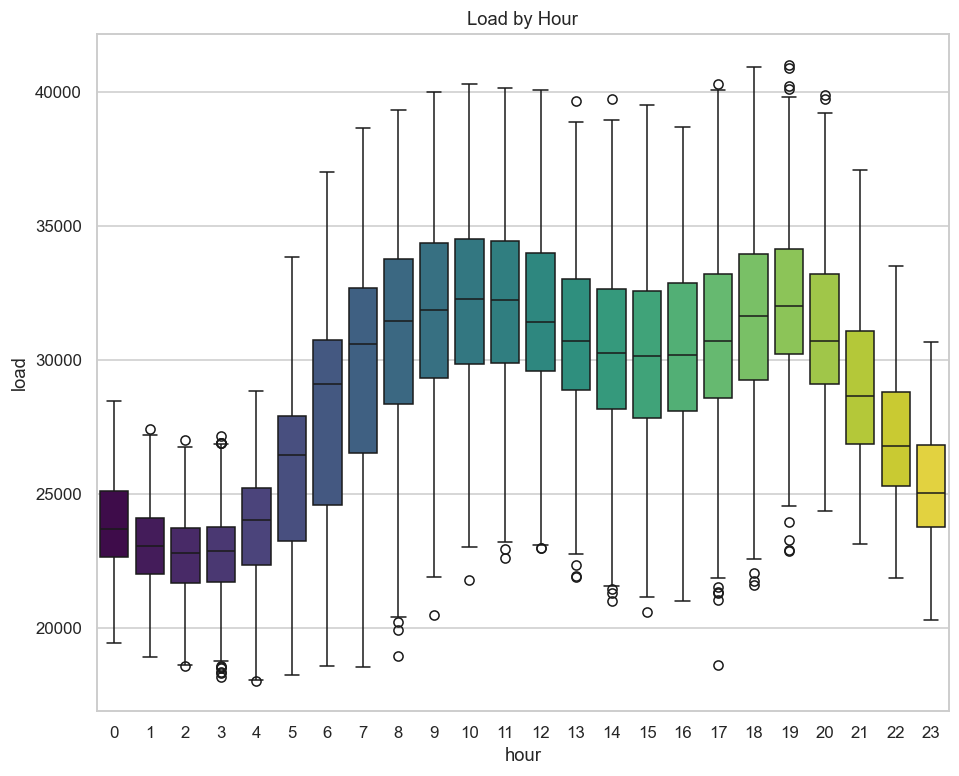

In [18]:
fig, ax = plt.subplots(figsize=(10, 8))

sns.boxplot(
    data=train_features,
    x="hour",
    y="load",
    hue="hour",
    palette="viridis",
    legend=False
)
ax.set_title("Load by Hour")

Text(0.5, 1.0, 'Load by Day of Week')

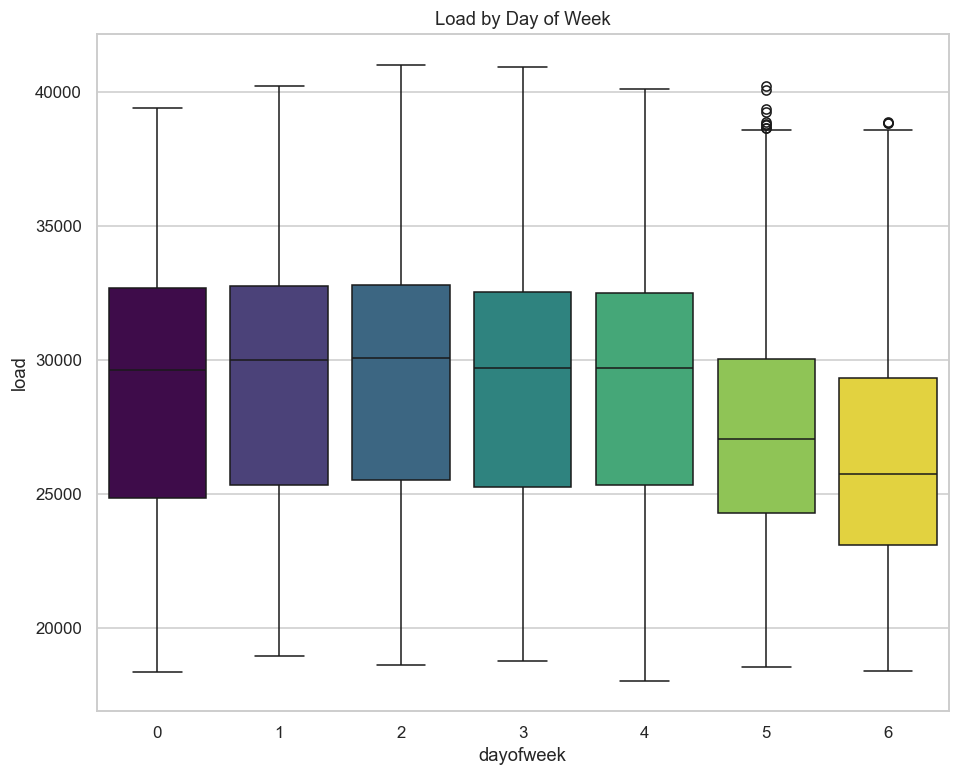

In [19]:
fig, ax = plt.subplots(figsize=(10, 8))

sns.boxplot(
    data=train_features,
    x="dayofweek",
    y="load",
    hue="dayofweek",
    palette="viridis",
    legend=False
)
ax.set_title("Load by Day of Week")

Text(0.5, 1.0, 'Load by Month')

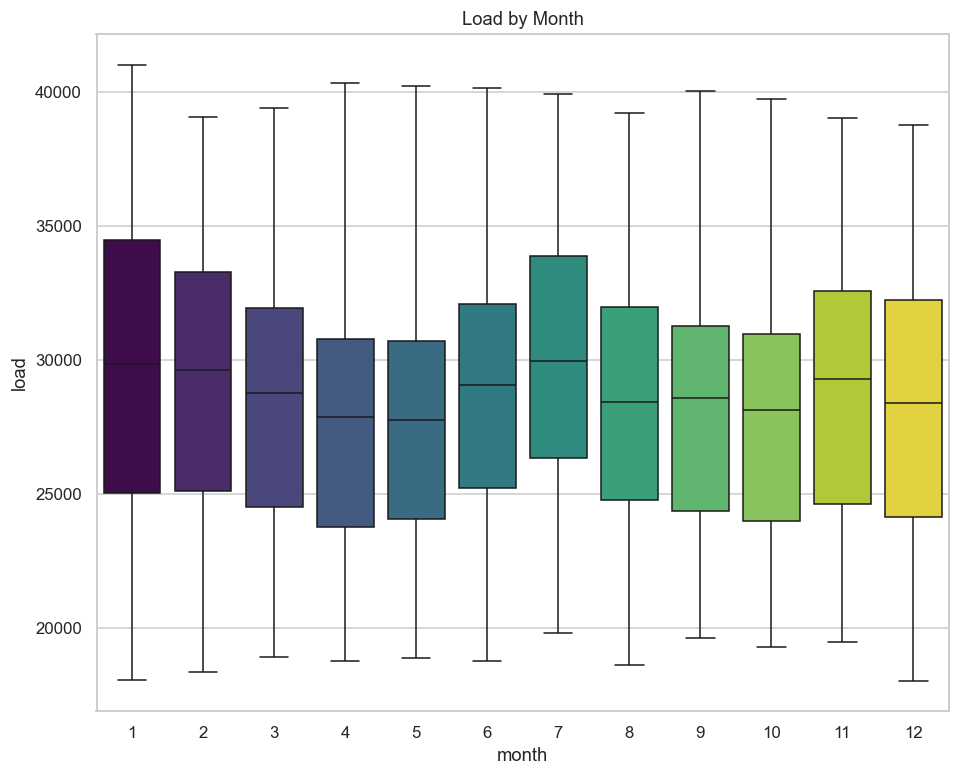

In [20]:
fig, ax = plt.subplots(figsize=(10, 8))

sns.boxplot(
    data=train_features,
    x="month",
    y="load",
    hue="month",
    palette="viridis",
    legend=False
)
ax.set_title("Load by Month")

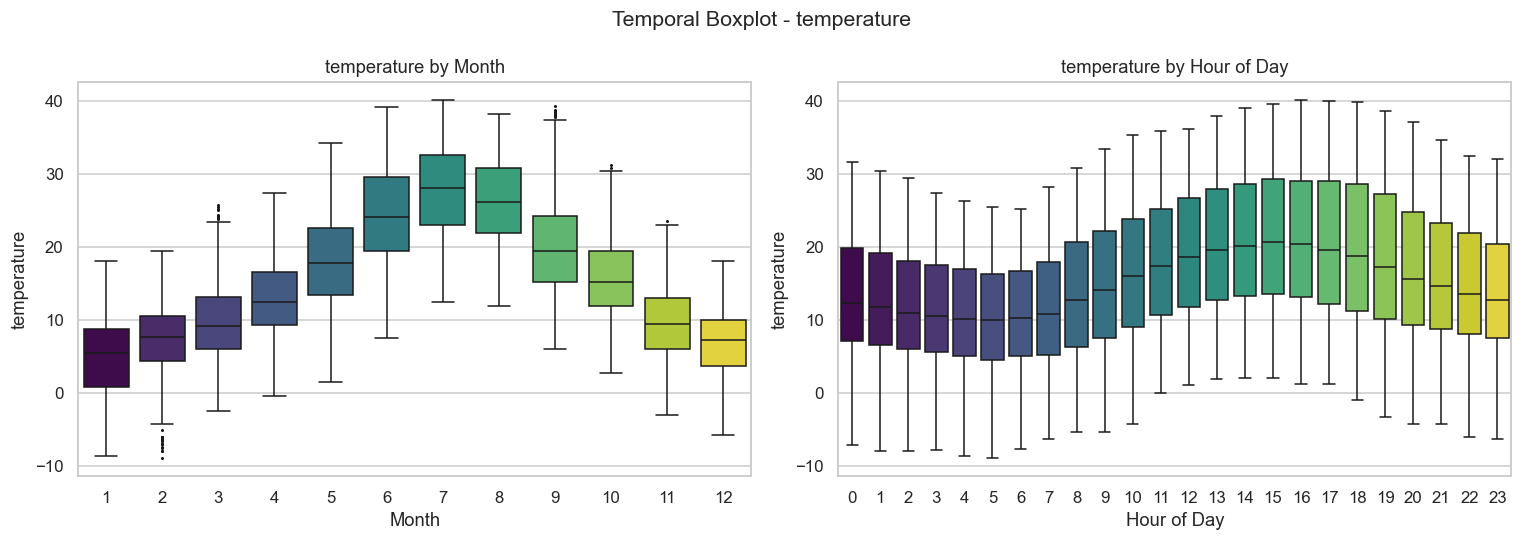

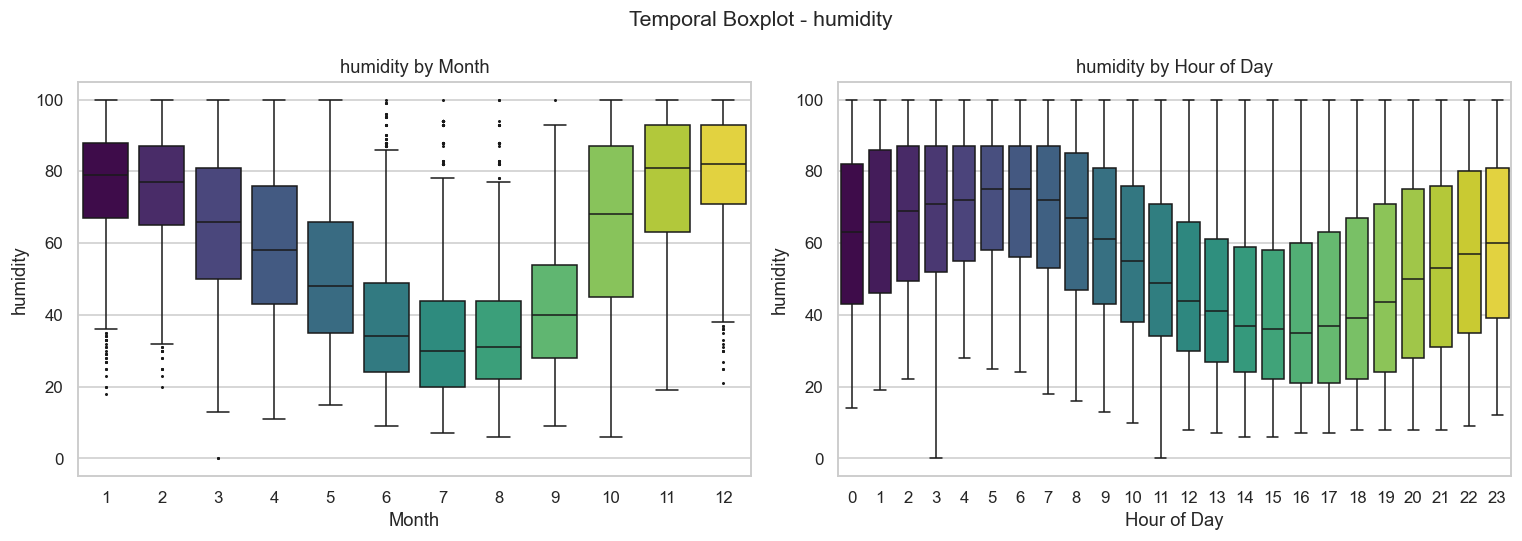

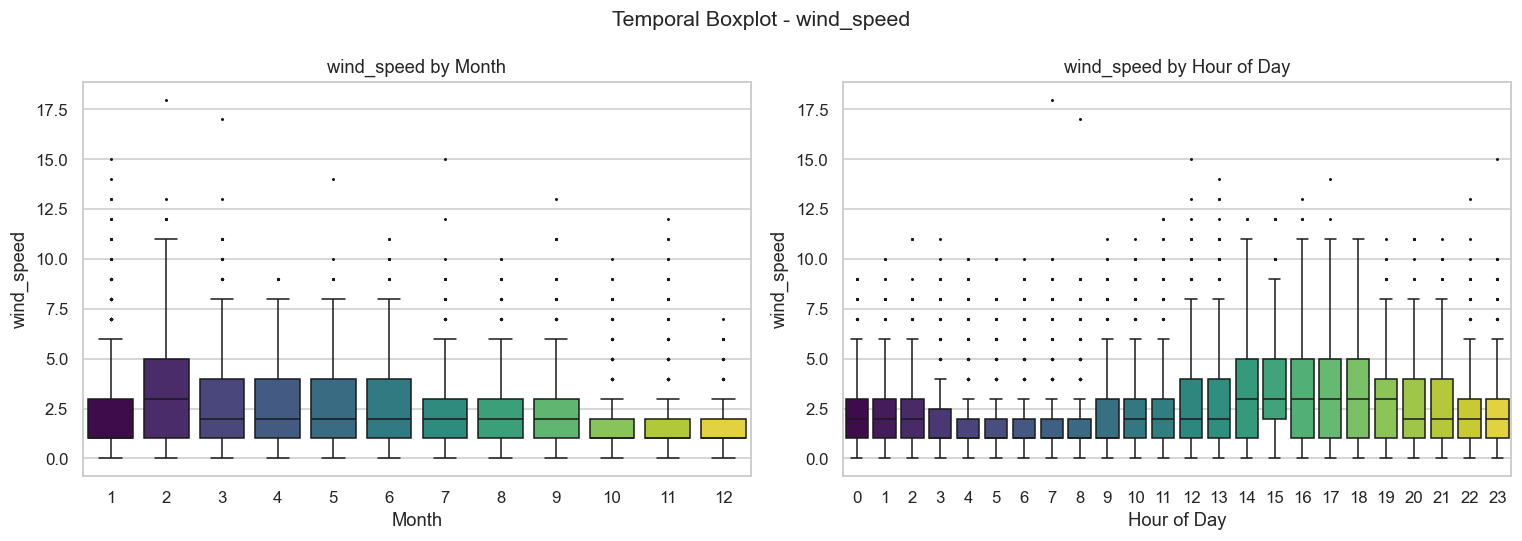

In [21]:
# Các đặc trưng thời gian dùng để phân tích từng biến
temporal_groups = {
    "temperature": ["month", "hour"],
    "humidity": ["month", "hour"],
    "wind_speed": ["month", "hour"]
}

orders = {
    "month": list(range(1, 13)),
    "hour": list(range(24))
}

group_labels = {
    "month": "Month",
    "hour": "Hour of Day"
}

# Vẽ boxplot riêng cho từng biến
for col, groups in temporal_groups.items():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, group in zip(axes, groups):
        sns.boxplot(
            data=train_features,
            x=group,
            y=col,
            hue=group,
            order=orders[group],
            hue_order=orders[group],
            palette="viridis",
            legend=False,
            dodge=False,
            ax=ax,
            showfliers=True,
            fliersize=1
        )
        ax.set_title(f"{col} by {group_labels[group]}")
        ax.set_xlabel(group_labels[group])
        ax.set_ylabel(col)
    fig.suptitle(
        f"Temporal Boxplot - {col}",
        fontsize=14
    )
    plt.tight_layout()
    plt.show()

#### **Biểu đồ điện năng tiêu thụ theo thời gian**

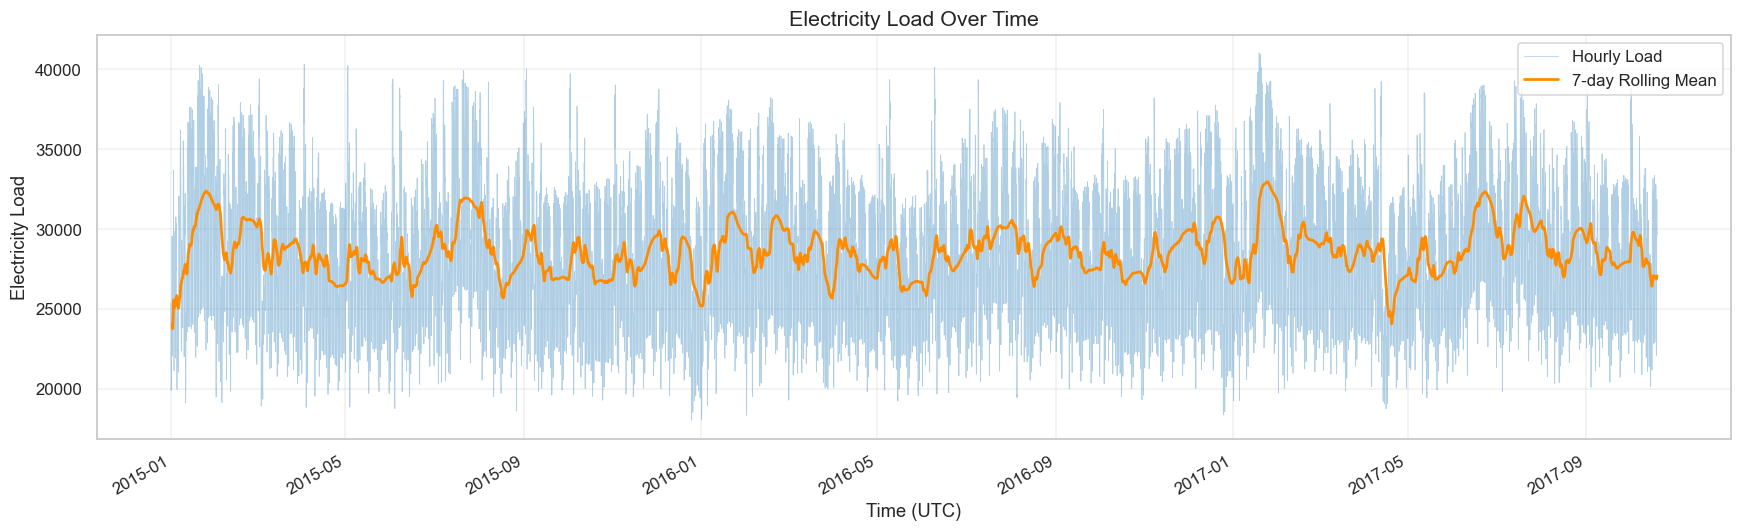

In [22]:
# Tính trung bình trượt 7 ngày (168 giờ)
load_series = train_df.set_index("time")["load"]
load_rolling = load_series.rolling(
    window=168,
    min_periods=24
).mean()

# Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(
    load_series.index,
    load_series,
    color=color_pal[0],
    linewidth=0.5,
    alpha=0.35,
    label="Hourly Load"
)
ax.plot(
    load_rolling.index,
    load_rolling,
    color="darkorange",
    linewidth=1.8,
    label="7-day Rolling Mean"
)
ax.set_title("Electricity Load Over Time", fontsize=14)
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Electricity Load")
ax.legend()
ax.grid(True, alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

#### **Biểu đồ tương quan giữa Load và Temp**

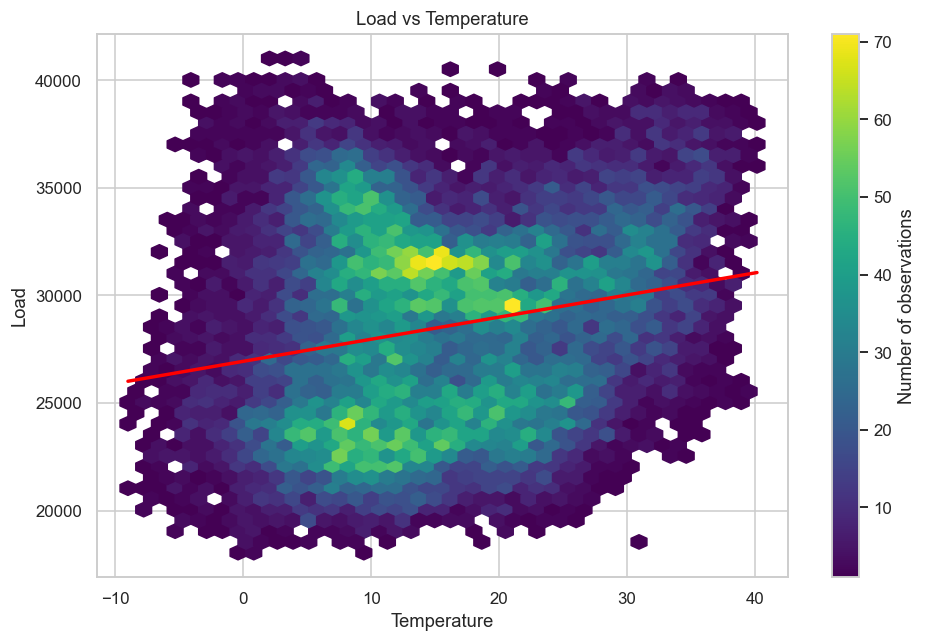

In [23]:
fig, ax = plt.subplots(figsize=(9, 6))

hb = ax.hexbin(
    train_df["temperature"],
    train_df["load"],
    gridsize=40,
    cmap="viridis",
    mincnt=1
)

plt.colorbar(hb, ax=ax, label="Number of observations")

sns.regplot(
    data=train_df,
    x="temperature",
    y="load",
    scatter=False,
    color="red",
    ci=None,
    ax=ax
)

ax.set_title("Load vs Temperature")
ax.set_xlabel("Temperature")
ax.set_ylabel("Load")

plt.tight_layout()
plt.show()


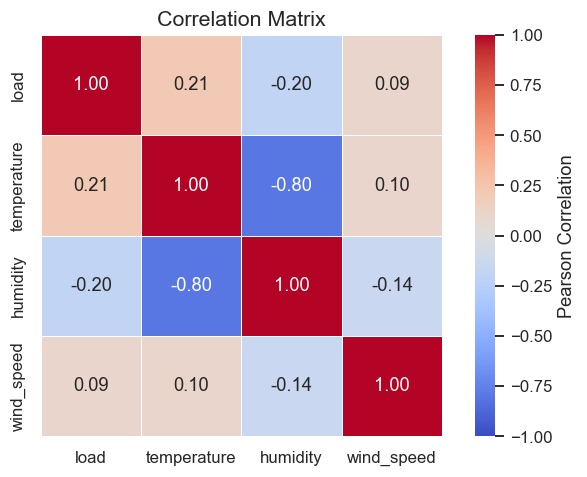

In [24]:
# Tính ma trận tương quan Pearson
corr_matrix = train_df[num_cols].corr(method="pearson")

# Vẽ heatmap
fig, ax = plt.subplots(figsize=(6.5, 4.5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation"},
    ax=ax
)

ax.set_title("Correlation Matrix", fontsize=14)

plt.tight_layout()
plt.show()

# Ghi kết quả vào log
log.info(
    "Ma trận tương quan Pearson:\n%s",
    corr_matrix.round(3).to_string()
)

log.info("Hoàn thành Correlation Matrix.")

## **4. Preprocessing**

### **4.1 Chuẩn hóa dữ liệu (StandardScaler)**


In [25]:
# Khởi tạo StandardScaler
scaler = StandardScaler()

# Fit trên Train và transform cả ba tập
train_values = scaler.fit_transform(train_df[num_cols])

val_values = scaler.transform(val_df[num_cols])

test_values = scaler.transform(test_df[num_cols])

# Chuyển kết quả về DataFrame để giữ tên cột và timestamp
train_scaled = pd.DataFrame(
    train_values,
    columns=num_cols,
    index=pd.DatetimeIndex(train_df["time"], name="time")
)

val_scaled = pd.DataFrame(
    val_values,
    columns=num_cols,
    index=pd.DatetimeIndex(val_df["time"], name="time")
)

test_scaled = pd.DataFrame(
    test_values,
    columns=num_cols,
    index=pd.DatetimeIndex(test_df["time"], name="time")
)

log.info("Hoàn thành chuẩn hóa dữ liệu bằng StandardScaler.")

In [26]:
# Kiểm tra thống kê trên tập Train sau chuẩn hóa
print("=== TRAIN DATA AFTER SCALING ===")
display(train_scaled.describe().T.round(3))

print("=== VALIDATION DATA ===")
print("Shape:", val_scaled.shape)
display(val_scaled.head())

print("=== TEST DATA ===")
print("Shape:", test_scaled.shape)

# Kiểm tra kích thước và thứ tự thời gian
assert len(train_scaled) + len(val_scaled) + len(test_scaled) == len(df)

assert train_scaled.index.max() < val_scaled.index.min()
assert val_scaled.index.max() < test_scaled.index.min()

assert train_scaled.index.is_monotonic_increasing
assert val_scaled.index.is_monotonic_increasing
assert test_scaled.index.is_monotonic_increasing

log.info("Kiểm tra dữ liệu sau Preprocessing thành công.")


=== TRAIN DATA AFTER SCALING ===


,count,mean,std,min,25%,50%,75%,max
load,24544.0,0.0,1.0,-2.317,-0.854,0.057,0.755,2.747
temperature,24544.0,0.0,1.0,-2.621,-0.759,-0.130,0.723,2.588
humidity,24544.0,0.0,1.0,-2.273,-0.871,0.010,0.892,1.733
wind_speed,24544.0,-0.0,1.0,-1.238,-0.735,-0.232,0.271,7.817


=== VALIDATION DATA ===
Shape: (5260, 4)


,load,temperature,humidity,wind_speed
time,,,,
2017-10-19 15:00:00+00:00,0.272099,0.193910,-0.470379,-0.231607
2017-10-19 16:00:00+00:00,0.259974,0.236258,-0.189957,1.277571
2017-10-19 17:00:00+00:00,0.530021,0.217202,0.090465,1.277571
2017-10-19 18:00:00+00:00,0.920430,0.025574,0.250706,0.774511
2017-10-19 19:00:00+00:00,0.689403,-0.164995,0.571189,-0.231607


=== TEST DATA ===
Shape: (5260, 4)


### **5. Feature Engineering cho ML và DL**

#### **Chuẩn bị dữ liệu cho LSTM**

In [27]:
# Hàm tạo Lag Window
def create_lstm_sequences(data, history=None, window_size=24):
    """
    Tạo chuỗi dữ liệu 3D cho LSTM.
    Mỗi mẫu sử dụng 24 giờ trước để dự báo load ở giờ tiếp theo.
    """

    # Ghép dữ liệu lịch sử nếu cần tạo window cho Validation/Test
    if history is not None:
        data_all = pd.concat([history.tail(window_size), data])
        start_pos = window_size
    else:
        data_all = data.copy()
        start_pos = window_size

    values = data_all[num_cols].to_numpy(dtype=np.float32)

    X, y = [], []

    for i in range(start_pos, len(data_all)):
        X.append(values[i - window_size:i])
        y.append(values[i, num_cols.index("load")])

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32)
    )

In [28]:
# Tạo Lag Window cho từng tập dữ liệu
X_train_lstm, y_train_lstm = create_lstm_sequences(
    train_scaled
)

X_val_lstm, y_val_lstm = create_lstm_sequences(
    val_scaled,
    history=train_scaled
)

X_test_lstm, y_test_lstm = create_lstm_sequences(
    test_scaled,
    history=pd.concat([train_scaled, val_scaled])
)

# Kiểm tra kích thước
print("Train:", X_train_lstm.shape, y_train_lstm.shape)
print("Validation:", X_val_lstm.shape, y_val_lstm.shape)
print("Test:", X_test_lstm.shape, y_test_lstm.shape)

log.info("Hoàn thành tạo Lag Window cho LSTM.")

Train: (24520, 24, 4) (24520,)
Validation: (5260, 24, 4) (5260,)
Test: (5260, 24, 4) (5260,)


#### **Rolling Features – Chỉ sử dụng cho XGBoost**

In [29]:
def create_xgb_features(data, history=None, window_size=24):
    """
    Tạo Lag Features và Rolling Features cho XGBoost.
    Target là load tại thời điểm hiện tại,
    sử dụng các giá trị lịch sử làm đầu vào.
    """

    # Giữ lại lịch sử để tạo features liên tục giữa các tập
    if history is not None:
        data_all = pd.concat([history.tail(window_size + 1), data])
    else:
        data_all = data.copy()

    X = pd.DataFrame(index=data_all.index)

    # Tạo Lag Features cho cả 4 biến
    for col in num_cols:
        for lag in range(1, window_size + 1):
            X[f"{col}_lag_{lag}"] = data_all[col].shift(lag)

    # Rolling Features: chỉ sử dụng dữ liệu quá khứ
    past_load = data_all["load"].shift(1)

    X["load_rolling_mean_6h"] = (
        past_load.rolling(window=6).mean()
    )

    X["load_rolling_std_24h"] = (
        past_load.rolling(window=24).std()
    )

    # Chênh lệch load giữa hai thời điểm cách nhau 24 giờ
    X["load_trend_24h"] = (
        data_all["load"].shift(1)
        - data_all["load"].shift(25)
    )

    # Target: load tại thời điểm dự báo
    y = data_all["load"].rename("target_load")

    # Chỉ lấy những mẫu thuộc tập dữ liệu hiện tại
    X = X.loc[data.index]
    y = y.loc[data.index]

    # Loại bỏ các mẫu chưa đủ dữ liệu lịch sử
    valid_idx = X.notna().all(axis=1) & y.notna()

    return X.loc[valid_idx], y.loc[valid_idx]

In [30]:
# Tạo features cho Train
X_train_xgb, y_train_xgb = create_xgb_features(
    train_scaled
)

# Validation sử dụng lịch sử cuối của Train
X_val_xgb, y_val_xgb = create_xgb_features(
    val_scaled,
    history=train_scaled
)

# Test sử dụng lịch sử của Train và Validation
X_test_xgb, y_test_xgb = create_xgb_features(
    test_scaled,
    history=pd.concat([train_scaled, val_scaled])
)

# Kiểm tra kích thước
print("Train:", X_train_xgb.shape, y_train_xgb.shape)
print("Validation:", X_val_xgb.shape, y_val_xgb.shape)
print("Test:", X_test_xgb.shape, y_test_xgb.shape)

log.info("Hoàn thành tạo Lag và Rolling Features cho XGBoost.")

Train: (24519, 99) (24519,)
Validation: (5260, 99) (5260,)
Test: (5260, 99) (5260,)


#### **Kiểm tra dữ liệu Feature Engineering**

In [31]:
print("=== XGBOOST FEATURES ===")
display(X_train_xgb.head())

print("\n=== LSTM INPUT ===")
print(X_train_lstm[0])

print("\n=== LSTM TARGET ===")
print(y_train_lstm[0])

log.info("Hoàn thành kiểm tra Feature Engineering.")

=== XGBOOST FEATURES ===


,load_lag_1,load_lag_2,load_lag_3,load_lag_4,load_lag_5,load_lag_6,load_lag_7,load_lag_8,load_lag_9,load_lag_10,...,wind_speed_lag_18,wind_speed_lag_19,wind_speed_lag_20,wind_speed_lag_21,wind_speed_lag_22,wind_speed_lag_23,wind_speed_lag_24,load_rolling_mean_6h,load_rolling_std_24h,load_trend_24h
time,,,,,,,,,,,,,,,,,,,,,
2015-01-02 00:00:00+00:00,-0.326853,-0.386814,0.105442,0.224482,0.101694,-0.117429,-0.464191,-1.090478,-1.198055,-1.107673,...,-1.237726,-1.237726,-1.237726,-0.734667,-0.734667,-0.734667,-0.734667,-0.066580,0.684446,0.371451
2015-01-02 01:00:00+00:00,-0.797505,-0.326853,-0.386814,0.105442,0.224482,0.101694,-0.117429,-0.464191,-1.090478,-1.198055,...,-0.734667,-1.237726,-1.237726,-1.237726,-0.734667,-0.734667,-0.734667,-0.179926,0.685606,0.121907
2015-01-02 02:00:00+00:00,-1.176893,-0.797505,-0.326853,-0.386814,0.105442,0.224482,0.101694,-0.117429,-0.464191,-1.090478,...,-0.734667,-0.734667,-1.237726,-1.237726,-1.237726,-0.734667,-0.734667,-0.393023,0.684086,0.105814
2015-01-02 03:00:00+00:00,-1.325473,-1.176893,-0.797505,-0.326853,-0.386814,0.105442,0.224482,0.101694,-0.117429,-0.464191,...,-0.734667,-0.734667,-0.734667,-1.237726,-1.237726,-1.237726,-0.734667,-0.651349,0.675813,0.276439
2015-01-02 04:00:00+00:00,-1.423351,-1.325473,-1.176893,-0.797505,-0.326853,-0.386814,0.105442,0.224482,0.101694,-0.117429,...,-0.734667,-0.734667,-0.734667,-0.734667,-1.237726,-1.237726,-1.237726,-0.906148,0.658874,0.403857



=== LSTM INPUT ===
[[-0.6983044  -2.2829552   0.2507065  -0.73466676]
 [-0.9194117  -2.2829552   0.2507065  -0.73466676]
 [-1.2827067  -2.403543    0.29076678 -0.73466676]
 [-1.6019125  -2.403543    0.29076678 -0.73466676]
 [-1.8272083  -2.403543    0.29076678 -0.73466676]
 [-1.9063483  -2.4823112   0.29076678 -1.2377261 ]
 [-1.8832016  -2.4823112   0.29076678 -1.2377261 ]
 [-1.8022978  -2.4823112   0.29076678 -1.2377261 ]
 [-1.8646841  -2.1822715   0.37088734 -0.73466676]
 [-1.7449819  -2.1822715   0.37088734 -0.73466676]
 [-1.3894025  -2.1822715   0.37088734 -0.73466676]
 [-1.1034842  -0.7743914   0.17058592 -0.73466676]
 [-0.97430277 -0.7743914   0.17058592 -0.73466676]
 [-0.84644413 -0.7743914   0.17058592 -0.73466676]
 [-0.8554824  -0.67236763 -0.39025807 -0.73466676]
 [-1.1076726  -0.5907771  -0.47037867 -0.73466676]
 [-1.1980555  -1.157223    0.4510079  -0.73466676]
 [-1.0904778  -0.859618    0.05040506 -0.73466676]
 [-0.46419078 -1.2100528   0.611249   -0.73466676]
 [-0.117429

## **6. Mô hình 1 – VAR (Statistical Baseline)**

VAR (Vector Autoregression) mô hình hóa đồng thời mối quan hệ động giữa 4 biến `load`, `temperature`, `humidity`, `wind_speed`. Mô hình tạo dự báo cho toàn bộ vector; khi đánh giá bài thực hành, chỉ lấy dự báo của `load`.

Quy trình: ADF trên Train → differencing nếu cần → chọn lag bằng AIC/BIC → fit VAR trên Train → walk-forward one-step trên Validation và Test.


In [32]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.api import VAR
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Hàm chuyển load đã chuẩn hóa về đơn vị ban đầu
def inverse_load_scale(values):
    load_idx = num_cols.index("load")
    values = np.asarray(values).reshape(-1)
    return values * scaler.scale_[load_idx] + scaler.mean_[load_idx]


# Hàm tính MAE, RMSE, MAPE trên đơn vị load ban đầu
def regression_metrics(y_true_scaled, y_pred_scaled):
    y_true = inverse_load_scale(y_true_scaled)
    y_pred = inverse_load_scale(y_pred_scaled)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(
        np.abs((y_true - y_pred) / np.maximum(np.abs(y_true), 1e-8))
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    }


### **6.1. Kiểm tra tính dừng bằng ADF**

Augmented Dickey-Fuller (ADF) kiểm định giả thuyết:

- H0: Chuỗi có nghiệm đơn vị, tức không dừng.
- H1: Chuỗi dừng.

Sử dụng dữ liệu Train đã chuẩn hóa. Nếu `p-value < 0.05`, bác bỏ H0 và xem chuỗi là dừng. Nếu không dừng, thực hiện sai phân bậc 1 cho biến đó.


In [33]:
alpha = 0.05
adf_rows = []
diff_cols = []

for col in num_cols:
    adf_stat, p_value, used_lag, n_obs, critical_values, _ = adfuller(
        train_scaled[col].dropna(),
        autolag="AIC"
    )

    is_stationary = p_value < alpha

    adf_rows.append({
        "Feature": col,
        "ADF Statistic": adf_stat,
        "p-value": p_value,
        "Used Lags": used_lag,
        "Stationarity": "Stationary" if is_stationary else "Non-stationary"
    })

    if not is_stationary:
        diff_cols.append(col)

adf_results = pd.DataFrame(adf_rows)
display(adf_results.round(5))

print("Các biến cần sai phân:", diff_cols if diff_cols else "Không có")

log.info("ADF test hoàn thành. Các biến cần sai phân: %s", diff_cols)


C:\Users\PC\AppData\Local\Temp\ipykernel_13872\1560659382.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, p_value, used_lag, n_obs, critical_values, _ = adfuller(
C:\Users\PC\AppData\Local\Temp\ipykernel_13872\1560659382.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, p_value, used_lag, n_obs, critical_values, _ = adfuller(
C:\Users\PC\AppData\

,Feature,ADF Statistic,p-value,Used Lags,Stationarity
0,load,-19.67837,0.00000,48,Stationary
1,temperature,-4.61800,0.00012,48,Stationary
2,humidity,-6.67265,0.00000,48,Stationary
3,wind_speed,-13.36214,0.00000,46,Stationary


Các biến cần sai phân: Không có


### **6.2. Differencing và chọn bậc trễ VAR**

Chỉ sai phân những biến không dừng theo kết quả ADF. Việc chọn bậc trễ dựa trên BIC để hạn chế mô hình quá phức tạp. `maxlags=48` là giới hạn tìm kiếm bậc trễ, không phải cửa sổ lag 24 giờ của XGBoost/LSTM.


In [34]:
# Chuẩn bị chuỗi đầu vào VAR từ Train
train_var_data = train_scaled[num_cols].copy()

# Sai phân bậc 1 cho các biến không dừng
for col in diff_cols:
    train_var_data[col] = train_var_data[col].diff()

train_var_data = train_var_data.dropna()

# Kiểm tra lại tính dừng sau sai phân (nếu có)
if diff_cols:
    for col in diff_cols:
        p_after_diff = adfuller(
            train_var_data[col].dropna(),
            autolag="AIC"
        )[1]
        print(f"{col} - p-value sau sai phân: {p_after_diff:.5f}")

        if p_after_diff >= alpha:
            print(
                f"Cảnh báo: {col} vẫn chưa dừng sau sai phân bậc 1. "
                "Cần xem xét thêm sai phân hoặc seasonal differencing."
            )

# Chọn bậc trễ bằng BIC, chỉ sử dụng Train
var_order_selection = VAR(train_var_data).select_order(maxlags=48)
print(var_order_selection.summary())

var_lag_order = var_order_selection.selected_orders["bic"]
if var_lag_order is None or var_lag_order < 1:
    var_lag_order = 1

var_lag_order = int(var_lag_order)
print(f"Bậc trễ VAR được chọn theo BIC: {var_lag_order}")

# Huấn luyện VAR trên Train
var_model = VAR(train_var_data).fit(var_lag_order)

log.info("Đã huấn luyện VAR với lag order = %d (BIC).", var_lag_order)


c:\Users\PC\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -1.124      -1.122      0.3251      -1.123
1       -10.15      -10.15   3.890e-05      -10.15
2       -11.15      -11.14   1.439e-05      -11.14
3       -11.25      -11.23   1.304e-05      -11.24
4       -11.31      -11.28   1.228e-05      -11.30
5       -11.34      -11.31   1.193e-05      -11.33
6       -11.37      -11.34   1.150e-05      -11.36
7       -11.41      -11.37   1.107e-05      -11.40
8       -11.44      -11.39   1.078e-05      -11.42
9       -11.45      -11.40   1.064e-05      -11.44
10      -11.50      -11.45   1.010e-05      -11.49
11      -11.54      -11.48   9.726e-06      -11.52
12      -11.59      -11.52   9.302e-06      -11.56
13      -11.70      -11.63   8.324e-06      -11.67
14      -11.73      -11.65   8.072e-06      -11.70
15      -11.75      -11.67   7.870e-06      -11.73
16      -11.81      -11.72   7.

c:\Users\PC\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


### **6.3. Walk-forward Forecasting cho VAR**

Ở mỗi thời điểm, VAR dự báo vector gồm 4 biến. Khi thời điểm đó đã quan sát được, vector thực tế được bổ sung vào lịch sử để dự báo bước tiếp theo. Đây là rolling one-step-ahead backtesting.

Nếu biến `load` đã được sai phân, dự báo sai phân được cộng với mức `load` quan sát gần nhất để đưa về thang đo đã chuẩn hóa ban đầu.


In [35]:
def walk_forward_var(model, initial_history, previous_levels, target_data, diff_cols):
    history_values = initial_history[num_cols].to_numpy(dtype=float)
    last_observed = previous_levels[num_cols].copy()
    load_idx = num_cols.index("load")

    predictions = []

    for _, current in target_data[num_cols].iterrows():

        # VAR dự báo toàn bộ vector 4 biến tại thời điểm kế tiếp
        forecast_vector = model.forecast(
            history_values[-model.k_ar:],
            steps=1
        )[0]

        # Chỉ lấy load để đánh giá
        predicted_load = forecast_vector[load_idx]

        # Nếu load đã sai phân, đưa dự báo về mức load đã chuẩn hóa
        if "load" in diff_cols:
            predicted_load += last_observed["load"]

        predictions.append(predicted_load)

        # Sau khi thời điểm hiện tại quan sát được,
        # cập nhật lịch sử bằng vector thực tế
        observed_for_var = current.copy()

        for col in diff_cols:
            observed_for_var[col] = current[col] - last_observed[col]

        history_values = np.vstack([
            history_values,
            observed_for_var[num_cols].to_numpy(dtype=float)
        ])

        last_observed = current.copy()

    updated_history = pd.DataFrame(history_values, columns=num_cols)

    return np.asarray(predictions), updated_history, last_observed


# Walk-forward trên Validation
var_val_pred_scaled, var_history_after_val, last_val_levels = walk_forward_var(
    model=var_model,
    initial_history=train_var_data,
    previous_levels=train_scaled.iloc[-1],
    target_data=val_scaled,
    diff_cols=diff_cols
)

# Tiếp tục walk-forward trên Test, sử dụng lịch sử đã cập nhật qua Validation
var_test_pred_scaled, _, _ = walk_forward_var(
    model=var_model,
    initial_history=var_history_after_val,
    previous_levels=last_val_levels,
    target_data=test_scaled,
    diff_cols=diff_cols
)

print("VAR Validation predictions:", var_val_pred_scaled.shape)
print("VAR Test predictions:", var_test_pred_scaled.shape)

log.info("Hoàn thành walk-forward forecasting cho VAR.")


VAR Validation predictions: (5260,)
VAR Test predictions: (5260,)


## **7. Mô hình 2 – XGBoost (Machine Learning)**

XGBoost nhận đầu vào là vector phẳng gồm 96 Lag Features (4 biến × 24 giờ) và 3 Rolling Features, tổng cộng 99 đặc trưng. Target là `load` tại thời điểm kế tiếp.

Sử dụng Validation để chọn `max_depth`, `n_estimators` và Early Stopping. Test chỉ được dùng sau khi đã chọn mô hình.


In [36]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [37]:
import inspect
from xgboost import XGBRegressor

# Thử một số cấu hình vừa phải để chọn hyperparameters bằng Validation
xgb_configs = [
    (3, 500), (3, 1000), (3, 1500),
    (5, 500), (5, 1000), (5, 1500),
    (7, 500), (7, 1000), (7, 1500)
]

xgb_records = []
fit_supports_early_stopping = (
    "early_stopping_rounds" in inspect.signature(XGBRegressor.fit).parameters
)

for max_depth, n_estimators in xgb_configs:

    params = {
        "objective": "reg:squarederror",
        "eval_metric": "rmse",
        "max_depth": max_depth,
        "n_estimators": n_estimators,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "random_state": 42,
        "n_jobs": -1,
        "tree_method": "hist"
    }

    if fit_supports_early_stopping:
        model = XGBRegressor(**params)
        model.fit(
            X_train_xgb,
            y_train_xgb,
            eval_set=[(X_val_xgb, y_val_xgb)],
            early_stopping_rounds=50,
            verbose=False
        )
    else:
        # XGBoost phiên bản mới nhận early_stopping_rounds trong constructor
        model = XGBRegressor(
            **params,
            early_stopping_rounds=50
        )
        model.fit(
            X_train_xgb,
            y_train_xgb,
            eval_set=[(X_val_xgb, y_val_xgb)],
            verbose=False
        )

    val_pred = model.predict(X_val_xgb)
    val_metrics = regression_metrics(y_val_xgb, val_pred)

    best_iteration = getattr(model, "best_iteration", n_estimators - 1)

    if best_iteration >= n_estimators - 5:
        print(
            f"Lưu ý: best_iteration gần giới hạn n_estimators={n_estimators}; "
            "có thể cần mở rộng khoảng tìm kiếm."
        )

    xgb_records.append({
        "max_depth": max_depth,
        "n_estimators": n_estimators,
        "best_iteration": int(best_iteration),
        "MAE": val_metrics["MAE"],
        "RMSE": val_metrics["RMSE"],
        "MAPE (%)": val_metrics["MAPE (%)"],
        "model": model
    })

# Chọn mô hình có RMSE thấp nhất trên Validation
xgb_tuning_results = pd.DataFrame([
    {k: v for k, v in record.items() if k != "model"}
    for record in xgb_records
]).sort_values("RMSE").reset_index(drop=True)

display(xgb_tuning_results.round(3))

best_xgb_record = min(xgb_records, key=lambda record: record["RMSE"])
best_xgb_model = best_xgb_record["model"]

print("Best max_depth:", best_xgb_record["max_depth"])
print("Best n_estimators:", best_xgb_record["n_estimators"])
print("Best iteration:", best_xgb_record["best_iteration"])

log.info(
    "XGBoost best config: max_depth=%d, n_estimators=%d, best_iteration=%d",
    best_xgb_record["max_depth"],
    best_xgb_record["n_estimators"],
    best_xgb_record["best_iteration"]
)


Lưu ý: best_iteration gần giới hạn n_estimators=500; có thể cần mở rộng khoảng tìm kiếm.
Lưu ý: best_iteration gần giới hạn n_estimators=1000; có thể cần mở rộng khoảng tìm kiếm.
Lưu ý: best_iteration gần giới hạn n_estimators=1500; có thể cần mở rộng khoảng tìm kiếm.
Lưu ý: best_iteration gần giới hạn n_estimators=500; có thể cần mở rộng khoảng tìm kiếm.
Lưu ý: best_iteration gần giới hạn n_estimators=1000; có thể cần mở rộng khoảng tìm kiếm.
Lưu ý: best_iteration gần giới hạn n_estimators=500; có thể cần mở rộng khoảng tìm kiếm.
Lưu ý: best_iteration gần giới hạn n_estimators=1000; có thể cần mở rộng khoảng tìm kiếm.
Lưu ý: best_iteration gần giới hạn n_estimators=1500; có thể cần mở rộng khoảng tìm kiếm.


,max_depth,n_estimators,best_iteration,MAE,RMSE,MAPE (%)
0,7,1500,1497,297.657,496.545,1.044
1,7,1000,999,298.274,497.633,1.046
2,7,500,497,301.693,501.366,1.058
3,5,1500,1215,314.053,511.712,1.104
4,5,1000,999,316.441,514.572,1.112
5,5,500,499,330.025,527.579,1.159
6,3,1500,1499,347.095,547.768,1.216
7,3,1000,998,360.988,562.962,1.263
8,3,500,499,394.616,602.545,1.377


Best max_depth: 7
Best n_estimators: 1500
Best iteration: 1497


In [38]:
# Dự báo Validation và Test bằng mô hình XGBoost tốt nhất
xgb_val_pred_scaled = best_xgb_model.predict(X_val_xgb)
xgb_test_pred_scaled = best_xgb_model.predict(X_test_xgb)

print("XGBoost Validation predictions:", xgb_val_pred_scaled.shape)
print("XGBoost Test predictions:", xgb_test_pred_scaled.shape)


XGBoost Validation predictions: (5260,)
XGBoost Test predictions: (5260,)


## **8. Mô hình 3 – LSTM (Deep Learning)**

Dữ liệu đầu vào có dạng `(batch_samples, 24, 4)`. Kiến trúc mạng theo yêu cầu:

`LSTM(64) → LSTM(32) → Dense(1)`

- Loss: Mean Squared Error (MSE)
- Optimizer: Adam
- Validation được sử dụng để theo dõi loss và Early Stopping.
- Test chỉ dùng để đánh giá cuối cùng.

Notebook dùng PyTorch để triển khai LSTM. Nếu môi trường chưa có PyTorch, cài đặt bằng `%pip install torch` rồi khởi động lại kernel.


In [39]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [40]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import copy

# Cố định seed để kết quả có khả năng tái lập
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)


class ElectricityLSTM(nn.Module):
    def __init__(self, n_features=4):
        super().__init__()

        self.lstm1 = nn.LSTM(
            input_size=n_features,
            hidden_size=64,
            batch_first=True
        )

        self.lstm2 = nn.LSTM(
            input_size=64,
            hidden_size=32,
            batch_first=True
        )

        self.output_layer = nn.Linear(32, 1)

    def forward(self, x):
        x, _ = self.lstm1(x)
        x, _ = self.lstm2(x)

        # Lấy hidden output tại bước thời gian cuối cùng
        x = x[:, -1, :]

        return self.output_layer(x)


# Chuyển NumPy arrays thành Tensor
X_train_tensor = torch.tensor(X_train_lstm, dtype=torch.float32)
y_train_tensor = torch.tensor(
    y_train_lstm.reshape(-1, 1),
    dtype=torch.float32
)

X_val_tensor = torch.tensor(X_val_lstm, dtype=torch.float32).to(device)
y_val_tensor = torch.tensor(
    y_val_lstm.reshape(-1, 1),
    dtype=torch.float32
).to(device)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

# Khởi tạo mô hình, Loss và Optimizer
lstm_model = ElectricityLSTM(n_features=len(num_cols)).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.001)

# Huấn luyện với Early Stopping dựa trên Validation Loss
max_epochs = 30
patience = 6
best_val_loss = float("inf")
epochs_without_improvement = 0
best_lstm_state = None

lstm_history = {
    "train_loss": [],
    "val_loss": []
}

for epoch in range(max_epochs):

    lstm_model.train()
    train_loss_sum = 0.0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad(set_to_none=True)

        predictions = lstm_model(X_batch)
        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * len(X_batch)

    train_loss = train_loss_sum / len(train_dataset)

    lstm_model.eval()
    with torch.no_grad():
        val_predictions = lstm_model(X_val_tensor)
        val_loss = criterion(val_predictions, y_val_tensor).item()

    lstm_history["train_loss"].append(train_loss)
    lstm_history["val_loss"].append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{max_epochs} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0

        best_lstm_state = {
            key: value.detach().cpu().clone()
            for key, value in lstm_model.state_dict().items()
        }
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping: Validation Loss không cải thiện.")
        break

# Khôi phục trọng số tốt nhất trên Validation
lstm_model.load_state_dict(best_lstm_state)
lstm_model.eval()

log.info("Hoàn thành huấn luyện LSTM. Best validation loss = %.6f", best_val_loss)


Training device: cpu
Epoch 01/30 | Train Loss: 0.421402 | Val Loss: 0.064720
Epoch 02/30 | Train Loss: 0.045176 | Val Loss: 0.036098
Epoch 03/30 | Train Loss: 0.033533 | Val Loss: 0.033170
Epoch 04/30 | Train Loss: 0.028432 | Val Loss: 0.027693
Epoch 05/30 | Train Loss: 0.024144 | Val Loss: 0.026803
Epoch 06/30 | Train Loss: 0.021507 | Val Loss: 0.023500
Epoch 07/30 | Train Loss: 0.019370 | Val Loss: 0.021377
Epoch 08/30 | Train Loss: 0.018198 | Val Loss: 0.020091
Epoch 09/30 | Train Loss: 0.017436 | Val Loss: 0.019228
Epoch 10/30 | Train Loss: 0.016876 | Val Loss: 0.018649
Epoch 11/30 | Train Loss: 0.016463 | Val Loss: 0.018230
Epoch 12/30 | Train Loss: 0.016162 | Val Loss: 0.017920
Epoch 13/30 | Train Loss: 0.015942 | Val Loss: 0.017829
Epoch 14/30 | Train Loss: 0.015791 | Val Loss: 0.018095
Epoch 15/30 | Train Loss: 0.015686 | Val Loss: 0.018624
Epoch 16/30 | Train Loss: 0.015568 | Val Loss: 0.019032
Epoch 17/30 | Train Loss: 0.015379 | Val Loss: 0.019093
Epoch 18/30 | Train Loss: 0

In [41]:
# Hàm dự báo LSTM
def predict_lstm(model, X):
    model.eval()

    X_tensor = torch.tensor(
        X,
        dtype=torch.float32
    ).to(device)

    with torch.no_grad():
        predictions = model(X_tensor).squeeze(1).cpu().numpy()

    return predictions


# Dự báo Validation và Test
lstm_val_pred_scaled = predict_lstm(lstm_model, X_val_lstm)
lstm_test_pred_scaled = predict_lstm(lstm_model, X_test_lstm)

print("LSTM Validation predictions:", lstm_val_pred_scaled.shape)
print("LSTM Test predictions:", lstm_test_pred_scaled.shape)


LSTM Validation predictions: (5260,)
LSTM Test predictions: (5260,)


## **9. Backtesting – Walk-forward Validation**

Để so sánh công bằng ba mô hình có cùng mục tiêu dự báo `load`, notebook triển khai **rolling one-step-ahead**:

1. Dùng 24 giờ lịch sử để dự báo `load` ở giờ tiếp theo.
2. Khi giờ đó đã xảy ra, cập nhật lịch sử bằng quan sát thực tế mới.
3. Tiếp tục dự báo giờ kế tiếp.

Với VAR, mô hình dự báo vector 4 biến và cập nhật lịch sử bằng vector quan sát thực tế. Với XGBoost/LSTM, các Lag Window đã được tạo sao cho mỗi mẫu chỉ sử dụng 24 quan sát trước thời điểm dự báo.

**Phân biệt:** Đây là walk-forward một bước tại mỗi thời điểm, không phải dự báo đệ quy nhiều bước từ một mốc cố định. XGBoost/LSTM chỉ dự báo `load`, nên muốn đưa dự báo `t+1` vào đầu vào để dự báo `t+2` trong khi vẫn cần 4 biến thì phải có thêm dự báo thời tiết tương lai. Không được lấy thời tiết tương lai thực tế nếu đang mô phỏng dự báo nhiều bước từ một mốc cố định.


In [42]:
# Kiểm tra số lượng dự báo phải khớp với số quan sát của từng tập
assert len(var_val_pred_scaled) == len(val_scaled)
assert len(xgb_val_pred_scaled) == len(val_scaled)
assert len(lstm_val_pred_scaled) == len(val_scaled)

assert len(var_test_pred_scaled) == len(test_scaled)
assert len(xgb_test_pred_scaled) == len(test_scaled)
assert len(lstm_test_pred_scaled) == len(test_scaled)


# Tổng hợp kết quả Validation và Test trên đơn vị load ban đầu
forecast_results = {
    "VAR": {
        "Validation": (val_scaled["load"].to_numpy(), var_val_pred_scaled),
        "Test": (test_scaled["load"].to_numpy(), var_test_pred_scaled)
    },
    "XGBoost": {
        "Validation": (y_val_xgb.to_numpy(), xgb_val_pred_scaled),
        "Test": (y_test_xgb.to_numpy(), xgb_test_pred_scaled)
    },
    "LSTM": {
        "Validation": (y_val_lstm, lstm_val_pred_scaled),
        "Test": (y_test_lstm, lstm_test_pred_scaled)
    }
}

metric_rows = []

for model_name, splits in forecast_results.items():
    for split_name, (y_true, y_pred) in splits.items():
        metrics = regression_metrics(y_true, y_pred)

        metric_rows.append({
            "Model": model_name,
            "Dataset": split_name,
            **metrics
        })

metrics_df = pd.DataFrame(metric_rows)

display(
    metrics_df.sort_values(["Dataset", "RMSE"]).reset_index(drop=True).round(3)
)

log.info(
    "Kết quả Backtesting (MAE, RMSE, MAPE):\n%s",
    metrics_df.to_string(index=False)
)


,Model,Dataset,MAE,RMSE,MAPE (%)
0,XGBoost,Test,279.523,435.087,0.975
1,LSTM,Test,391.695,545.410,1.384
2,VAR,Test,417.905,637.755,1.488
3,XGBoost,Validation,297.657,496.545,1.044
4,LSTM,Validation,410.058,605.701,1.458
5,VAR,Validation,442.545,731.531,1.572


### **Trực quan hóa dự báo trên Test**

Biểu đồ hiển thị 14 ngày đầu của tập Test để quan sát khả năng bám sát biến động thực tế. Bảng metrics phía trên vẫn được tính trên toàn bộ tập Test.


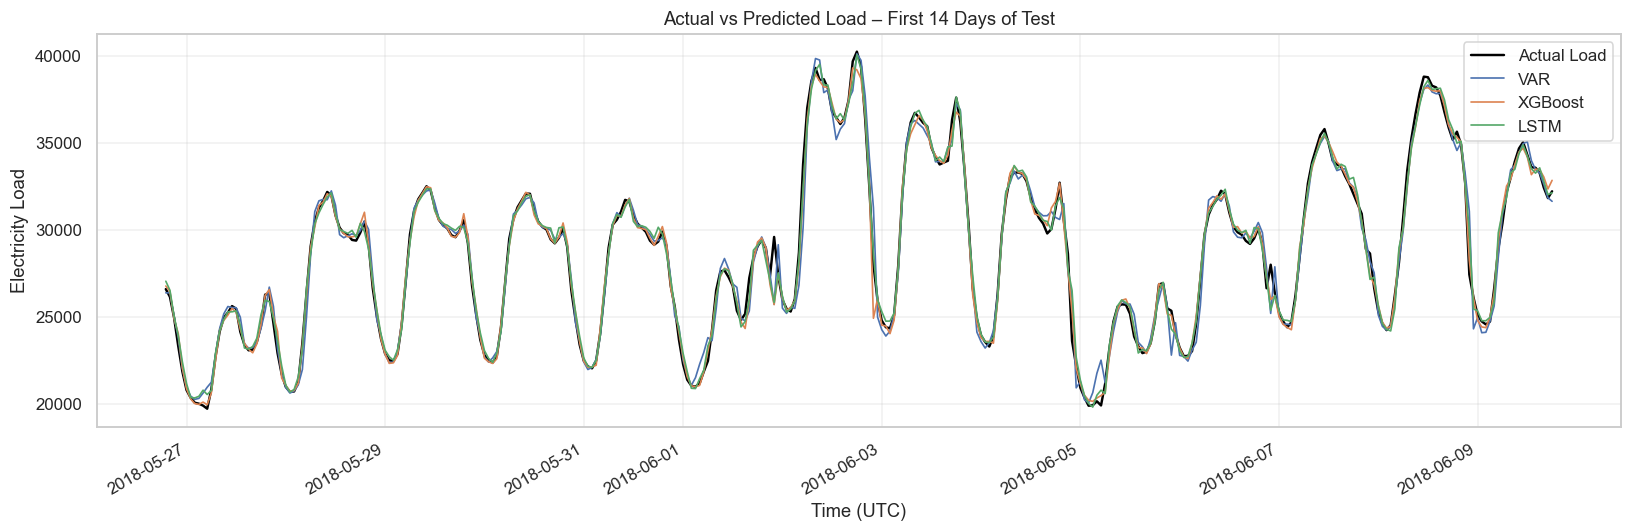

In [43]:
# Hiển thị 14 ngày đầu của Test (24 giờ × 14 ngày)
plot_steps = min(24 * 14, len(test_scaled))
plot_time = test_scaled.index[:plot_steps]

actual_load = inverse_load_scale(test_scaled["load"].to_numpy()[:plot_steps])
var_load_pred = inverse_load_scale(var_test_pred_scaled[:plot_steps])
xgb_load_pred = inverse_load_scale(xgb_test_pred_scaled[:plot_steps])
lstm_load_pred = inverse_load_scale(lstm_test_pred_scaled[:plot_steps])

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(plot_time, actual_load, label="Actual Load", color="black", linewidth=1.6)
ax.plot(plot_time, var_load_pred, label="VAR", linewidth=1.1)
ax.plot(plot_time, xgb_load_pred, label="XGBoost", linewidth=1.1)
ax.plot(plot_time, lstm_load_pred, label="LSTM", linewidth=1.1)

ax.set_title("Actual vs Predicted Load – First 14 Days of Test")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Electricity Load")
ax.legend()
ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

log.info("Hoàn thành trực quan hóa dự báo trên Test.")


### **Tạo Score / Model Evaluation Table**

In [45]:
# Tổng hợp bảng đánh giá các mô hình
evaluation_table = metrics_df[
    ["Model", "Dataset", "RMSE", "MAE", "MAPE (%)"]
].copy()

# Sắp xếp theo tập dữ liệu và RMSE
dataset_order = ["Validation", "Test"]

evaluation_table["Dataset"] = pd.Categorical(
    evaluation_table["Dataset"],
    categories=dataset_order,
    ordered=True
)

evaluation_table = (
    evaluation_table
    .sort_values(["Dataset", "RMSE"])
    .reset_index(drop=True)
)

print("=== MODEL EVALUATION TABLE ===")
display(evaluation_table.round(3))

log.info("Hoàn thành tạo Model Evaluation Table.")

=== MODEL EVALUATION TABLE ===


,Model,Dataset,RMSE,MAE,MAPE (%)
0,XGBoost,Validation,496.545,297.657,1.044
1,LSTM,Validation,605.701,410.058,1.458
2,VAR,Validation,731.531,442.545,1.572
3,XGBoost,Test,435.087,279.523,0.975
4,LSTM,Test,545.410,391.695,1.384
5,VAR,Test,637.755,417.905,1.488


In [46]:
# Tạo bảng xếp hạng trên Validation và Test
def create_model_ranking(data, dataset_name):

    ranking = (
        data[data["Dataset"] == dataset_name]
        .sort_values("RMSE")
        .reset_index(drop=True)
        .copy()
    )

    ranking.insert(0, "Rank", range(1, len(ranking) + 1))

    ranking["Status"] = [
        "Best Model" if i == 0 else ""
        for i in range(len(ranking))
    ]

    return ranking


validation_ranking = create_model_ranking(
    evaluation_table, "Validation"
)

test_ranking = create_model_ranking(
    evaluation_table, "Test"
)

print("=== VALIDATION MODEL RANKING ===")
display(validation_ranking.round(3))

print("=== TEST MODEL RANKING ===")
display(test_ranking.round(3))

log.info("Hoàn thành bảng xếp hạng mô hình.")

=== VALIDATION MODEL RANKING ===


,Rank,Model,Dataset,RMSE,MAE,MAPE (%),Status
0,1,XGBoost,Validation,496.545,297.657,1.044,Best Model
1,2,LSTM,Validation,605.701,410.058,1.458,
2,3,VAR,Validation,731.531,442.545,1.572,


=== TEST MODEL RANKING ===


,Rank,Model,Dataset,RMSE,MAE,MAPE (%),Status
0,1,XGBoost,Test,435.087,279.523,0.975,Best Model
1,2,LSTM,Test,545.410,391.695,1.384,
2,3,VAR,Test,637.755,417.905,1.488,


Xuất kết quả vào folder results

In [48]:
%pip install openpyxl

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [49]:
# Xác định thư mục gốc của project
project_root = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

# Tạo thư mục results nếu chưa tồn tại
RESULTS_DIR = project_root / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Đường dẫn lưu kết quả
csv_file = RESULTS_DIR / "model_evaluation.csv"
excel_file = RESULTS_DIR / "model_evaluation.xlsx"
val_file = RESULTS_DIR / "validation_ranking.csv"
test_file = RESULTS_DIR / "test_ranking.csv"

# Lưu bảng tổng hợp CSV
evaluation_table.to_csv(
    csv_file,
    index=False,
    encoding="utf-8-sig"
)

# Lưu bảng xếp hạng CSV
validation_ranking.to_csv(
    val_file,
    index=False,
    encoding="utf-8-sig"
)

test_ranking.to_csv(
    test_file,
    index=False,
    encoding="utf-8-sig"
)

# Lưu tất cả bảng vào một file Excel
with pd.ExcelWriter(excel_file, engine="openpyxl") as writer:

    evaluation_table.to_excel(
        writer,
        sheet_name="All Results",
        index=False
    )

    validation_ranking.to_excel(
        writer,
        sheet_name="Validation",
        index=False
    )

    test_ranking.to_excel(
        writer,
        sheet_name="Test",
        index=False
    )

print("=== MODEL EVALUATION FILES ===")

for file in [csv_file, excel_file, val_file, test_file]:
    print(f"Saved: {file.resolve()}")

log.info("Đã lưu toàn bộ Model Evaluation Tables vào: %s", RESULTS_DIR.resolve())

=== MODEL EVALUATION FILES ===
Saved: D:\Practice_Time_Series_Data\Practice_4\total_practice\Practice_4\results\model_evaluation.csv
Saved: D:\Practice_Time_Series_Data\Practice_4\total_practice\Practice_4\results\model_evaluation.xlsx
Saved: D:\Practice_Time_Series_Data\Practice_4\total_practice\Practice_4\results\validation_ranking.csv
Saved: D:\Practice_Time_Series_Data\Practice_4\total_practice\Practice_4\results\test_ranking.csv


## **Model Summaries – VAR, XGBoost và LSTM**

In [51]:
# Đường dẫn thư mục lưu Model Summary
PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name.lower() == "notebooks"
    else Path.cwd()
)

RESULTS_DIR = PROJECT_ROOT / "results"
MODEL_SUMMARY_DIR = RESULTS_DIR / "model_summaries"
MODEL_SUMMARY_DIR.mkdir(parents=True, exist_ok=True)

print("Model summary directory:", MODEL_SUMMARY_DIR.resolve())
log.info("Model summary directory: %s", MODEL_SUMMARY_DIR.resolve())

Model summary directory: D:\Practice_Time_Series_Data\Practice_4\total_practice\Practice_4\results\model_summaries


### **VAR Model Summary**

In [52]:
# Tạo VAR Model Summary
var_stats_summary = var_model.summary()
var_stats_text = (
    var_stats_summary.as_text()
    if hasattr(var_stats_summary, "as_text")
    else str(var_stats_summary)
)

var_summary_lines = [
    "VAR MODEL SUMMARY - ELECTRICITY LOAD + WEATHER",
    "=" * 78,
    f"Training observations: {len(train_var_data):,}",
    f"Training period: {train_df['time'].min()} -> {train_df['time'].max()}",
    f"Variables: {', '.join(num_cols)}",
    f"ADF significance level: {alpha}",
    f"Variables differenced: {diff_cols if diff_cols else 'None'}",
    f"Selected lag order (BIC): {var_lag_order}",
    f"Fitted observations: {var_model.nobs:,}",
    f"AIC: {var_model.aic:.6f}",
    f"BIC: {var_model.bic:.6f}",
    f"HQIC: {var_model.hqic:.6f}",
    f"FPE: {var_model.fpe:.6f}",
    "",
    "ADF TEST RESULTS",
    "-" * 78,
    adf_results.to_string(index=False),
    "",
    "STATSMODELS VAR SUMMARY",
    "-" * 78,
    var_stats_text
]

var_summary_text = "\n".join(var_summary_lines)
var_summary_path = MODEL_SUMMARY_DIR / "VAR_summary.txt"
var_summary_path.write_text(var_summary_text, encoding="utf-8")

print(var_summary_text)
print("\nSaved:", var_summary_path.resolve())
log.info("Saved VAR Model Summary: %s", var_summary_path.resolve())


VAR MODEL SUMMARY - ELECTRICITY LOAD + WEATHER
Training observations: 24,544
Training period: 2014-12-31 23:00:00+00:00 -> 2017-10-19 14:00:00+00:00
Variables: load, temperature, humidity, wind_speed
ADF significance level: 0.05
Variables differenced: None
Selected lag order (BIC): 26
Fitted observations: 24,518
AIC: -12.329365
BIC: -12.190487
HQIC: -12.284372
FPE: 0.000004

ADF TEST RESULTS
------------------------------------------------------------------------------
    Feature  ADF Statistic      p-value  Used Lags Stationarity
       load     -19.678369 0.000000e+00         48   Stationary
temperature      -4.617997 1.196551e-04         48   Stationary
   humidity      -6.672654 4.546661e-09         48   Stationary
 wind_speed     -13.362136 5.401614e-25         46   Stationary

STATSMODELS VAR SUMMARY
------------------------------------------------------------------------------
  Summary of Regression Results   
Model:                         VAR
Method:                        O

### **XGBoost Model Summary**

In [53]:
# Tạo XGBoost Model Summary
xgb_params = best_xgb_model.get_params()
xgb_best_iteration = int(
    getattr(best_xgb_model, "best_iteration", best_xgb_record["best_iteration"])
)
xgb_best_rounds = xgb_best_iteration + 1

# Lấy Feature Importance
xgb_importance = pd.DataFrame({
    "Feature": X_train_xgb.columns,
    "Importance": best_xgb_model.feature_importances_
}).sort_values("Importance", ascending=False).reset_index(drop=True)

xgb_top_features = xgb_importance.head(15)

xgb_summary_lines = [
    "XGBOOST MODEL SUMMARY - ELECTRICITY LOAD FORECASTING",
    "=" * 78,
    f"Training samples: {len(X_train_xgb):,}",
    f"Validation samples: {len(X_val_xgb):,}",
    f"Number of input features: {X_train_xgb.shape[1]}",
    "Input: 24-hour lag features for load, temperature, humidity, wind_speed",
    "Additional features: rolling mean (6h), rolling std (24h), load trend (24h)",
    "Target: load at the next time step",
    "",
    "SELECTED HYPERPARAMETERS (BASED ON VALIDATION RMSE)",
    "-" * 78,
    f"Objective: {xgb_params.get('objective')}",
    f"Evaluation metric: {xgb_params.get('eval_metric')}",
    f"Booster: {xgb_params.get('booster')}",
    f"Tree method: {xgb_params.get('tree_method')}",
    f"Max depth: {best_xgb_record['max_depth']}",
    f"Configured n_estimators: {best_xgb_record['n_estimators']}",
    f"Best iteration (0-based): {xgb_best_iteration}",
    f"Best boosting rounds: {xgb_best_rounds}",
    "Early stopping rounds: 50",
    f"Learning rate: {xgb_params.get('learning_rate')}",
    f"Subsample: {xgb_params.get('subsample')}",
    f"Column subsample: {xgb_params.get('colsample_bytree')}",
    f"Random state: {xgb_params.get('random_state')}",
    "",
    "VALIDATION METRICS (ORIGINAL LOAD SCALE)",
    "-" * 78,
    f"MAE: {best_xgb_record['MAE']:.6f}",
    f"RMSE: {best_xgb_record['RMSE']:.6f}",
    f"MAPE: {best_xgb_record['MAPE (%)']:.6f}%",
    "",
    "TOP 15 FEATURE IMPORTANCES",
    "-" * 78,
    xgb_top_features.to_string(index=False, formatters={"Importance": "{:.6f}".format})
]

xgb_summary_text = "\n".join(xgb_summary_lines)
xgb_summary_path = MODEL_SUMMARY_DIR / "XGBoost_summary.txt"
xgb_summary_path.write_text(xgb_summary_text, encoding="utf-8")

# Lưu riêng bảng Feature Importance và kết quả tuning để tiện phân tích
xgb_importance.to_csv(
    MODEL_SUMMARY_DIR / "XGBoost_feature_importance.csv",
    index=False,
    encoding="utf-8-sig"
)

if "xgb_tuning_results" in globals():
    xgb_tuning_results.to_csv(
        MODEL_SUMMARY_DIR / "XGBoost_tuning_results.csv",
        index=False,
        encoding="utf-8-sig"
    )

print(xgb_summary_text)
print("\nSaved:", xgb_summary_path.resolve())
log.info("Saved XGBoost Model Summary: %s", xgb_summary_path.resolve())


XGBOOST MODEL SUMMARY - ELECTRICITY LOAD FORECASTING
Training samples: 24,519
Validation samples: 5,260
Number of input features: 99
Input: 24-hour lag features for load, temperature, humidity, wind_speed
Additional features: rolling mean (6h), rolling std (24h), load trend (24h)
Target: load at the next time step

SELECTED HYPERPARAMETERS (BASED ON VALIDATION RMSE)
------------------------------------------------------------------------------
Objective: reg:squarederror
Evaluation metric: rmse
Booster: None
Tree method: hist
Max depth: 7
Configured n_estimators: 1500
Best iteration (0-based): 1497
Best boosting rounds: 1498
Early stopping rounds: 50
Learning rate: 0.05
Subsample: 0.8
Column subsample: 0.8
Random state: 42

VALIDATION METRICS (ORIGINAL LOAD SCALE)
------------------------------------------------------------------------------
MAE: 297.657315
RMSE: 496.544950
MAPE: 1.044094%

TOP 15 FEATURE IMPORTANCES
---------------------------------------------------------------------

### **LSTM Model Summary**

In [54]:
# Tạo LSTM Model Summary
lstm_total_params = sum(p.numel() for p in lstm_model.parameters())
lstm_trainable_params = sum(
    p.numel() for p in lstm_model.parameters() if p.requires_grad
)

lstm_epochs_completed = len(lstm_history["train_loss"])
lstm_best_epoch = int(np.argmin(lstm_history["val_loss"]) + 1)
lstm_best_train_loss = float(lstm_history["train_loss"][lstm_best_epoch - 1])
lstm_best_validation_loss = float(lstm_history["val_loss"][lstm_best_epoch - 1])

lstm_optimizer_name = type(optimizer).__name__
lstm_learning_rate = optimizer.param_groups[0]["lr"]
lstm_batch_size = train_loader.batch_size
lstm_input_shape = tuple(X_train_lstm.shape[1:])

lstm_summary_lines = [
    "LSTM MODEL SUMMARY - ELECTRICITY LOAD FORECASTING",
    "=" * 78,
    f"Training samples: {len(X_train_lstm):,}",
    f"Validation samples: {len(X_val_lstm):,}",
    f"Test samples: {len(X_test_lstm):,}",
    f"Input shape per sample: {lstm_input_shape}",
    f"Input features: {', '.join(num_cols)}",
    "Target: next-step load",
    "",
    "NETWORK ARCHITECTURE",
    "-" * 78,
    f"Layer 1: LSTM(input_size={lstm_model.lstm1.input_size}, hidden_size={lstm_model.lstm1.hidden_size})",
    f"Layer 2: LSTM(input_size={lstm_model.lstm2.input_size}, hidden_size={lstm_model.lstm2.hidden_size})",
    f"Output layer: Linear(in_features={lstm_model.output_layer.in_features}, out_features={lstm_model.output_layer.out_features})",
    f"Total parameters: {lstm_total_params:,}",
    f"Trainable parameters: {lstm_trainable_params:,}",
    "",
    "TRAINING CONFIGURATION",
    "-" * 78,
    f"Loss function: {type(criterion).__name__}",
    f"Optimizer: {lstm_optimizer_name}",
    f"Learning rate: {lstm_learning_rate}",
    f"Batch size: {lstm_batch_size}",
    f"Maximum epochs: {max_epochs}",
    f"Completed epochs: {lstm_epochs_completed}",
    f"Early stopping patience: {patience}",
    f"Best epoch: {lstm_best_epoch}",
    f"Training device: {device}",
    "",
    "BEST EPOCH LOSSES (STANDARDIZED SCALE)",
    "-" * 78,
    f"Train MSE: {lstm_best_train_loss:.8f}",
    f"Validation MSE: {lstm_best_validation_loss:.8f}",
    "Note: These losses are calculated on standardized load values.",
]

lstm_summary_text = "\n".join(lstm_summary_lines)
lstm_summary_path = MODEL_SUMMARY_DIR / "LSTM_summary.txt"
lstm_summary_path.write_text(lstm_summary_text, encoding="utf-8")

# Lưu lịch sử huấn luyện để có thể vẽ Learning Curve hoặc phân tích overfitting
lstm_history_df = pd.DataFrame({
    "Epoch": range(1, lstm_epochs_completed + 1),
    "Train Loss": lstm_history["train_loss"],
    "Validation Loss": lstm_history["val_loss"]
})
lstm_history_df.to_csv(
    MODEL_SUMMARY_DIR / "LSTM_training_history.csv",
    index=False,
    encoding="utf-8-sig"
)

print(lstm_summary_text)
print("\nSaved:", lstm_summary_path.resolve())
log.info("Saved LSTM Model Summary: %s", lstm_summary_path.resolve())


LSTM MODEL SUMMARY - ELECTRICITY LOAD FORECASTING
Training samples: 24,520
Validation samples: 5,260
Test samples: 5,260
Input shape per sample: (24, 4)
Input features: load, temperature, humidity, wind_speed
Target: next-step load

NETWORK ARCHITECTURE
------------------------------------------------------------------------------
Layer 1: LSTM(input_size=4, hidden_size=64)
Layer 2: LSTM(input_size=64, hidden_size=32)
Output layer: Linear(in_features=32, out_features=1)
Total parameters: 30,497
Trainable parameters: 30,497

TRAINING CONFIGURATION
------------------------------------------------------------------------------
Loss function: MSELoss
Optimizer: Adam
Learning rate: 0.001
Batch size: 128
Maximum epochs: 30
Completed epochs: 19
Early stopping patience: 6
Best epoch: 13
Training device: cpu

BEST EPOCH LOSSES (STANDARDIZED SCALE)
------------------------------------------------------------------------------
Train MSE: 0.01594182
Validation MSE: 0.01782875
Note: These losses ar